# Quantum Centauro: reconstruction, decisions and cost

**Can a circuit-based candidate selector fit into Centauro jet reconstruction
without changing the final jets in our measured sample? What does it cost?**

This demo answers those questions using results included in this repository.
It compares **FastJet Centauro**, **Direct Centauro with classical selection**,
and **Direct Centauro with an Aer-simulated selector**. We first look at the
jets, then inspect the decisions, and finally compare timings.

**Run All** regenerates every comparison, table and plot from bundled data.
It does not launch detector reconstruction or a quantum simulator. Change
`EVENT = 4` below to inspect another of the ten included events. The numbers
are recorded measurements, not newly simulated or illustrative jet data.

## 1. What changes between the methods?

A jet groups particle momenta into a reconstructed object. A sequential
clustering algorithm repeatedly builds pair/beam candidates, chooses an
action, merges a pair or finalizes an object, and recomputes the candidates.

| Method | Candidate selection and execution | Role in this demo |
| :-- | :-- | :-- |
| **FastJet Centauro** | Established FastJet implementation, including its own area handling. | Contextual reconstruction and timing reference. |
| **Direct classical** | C++ enumerates Centauro candidates and selects the deterministic minimum. | Baseline for the Direct implementation. |
| **Direct Aer (active)** | The same Direct C++ loop sends candidate distances to a local circuit simulator; a valid returned index determines the action. | Tests the changed selection boundary. |

`particles → candidates → selection → merge/finalize → repeat → final jets`

Only **selection** changes between the Direct modes. The worker does not
receive particle identities or momenta. For positive distances the maintained
selector uses inverse-power amplitudes, giving $P(i)\propto d_i^{-2a}$;
these measurements use $a=3$ and 512 shots. Finite sampling need not return a
minimum every time. Invalid or failed responses retain the classical action.

**Shadow mode** queries the worker but still applies the classical choice.
It is a diagnostic, not a fourth independent reconstruction algorithm. The
three displayed reconstructions are actual stored outputs, not copies of one
method relabeled as another.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

# Discover the checkout from either the repository or notebook directory.
REPO = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'notebooks/data/jets.csv').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Open this notebook from the repository or notebooks directory.')
DATA = REPO / 'notebooks/data'
MEASUREMENTS = REPO / 'benchmark/results/2026-10-04'
EVENT = 4  # Any included event index, 0–9.

particles = pd.read_csv(DATA / 'particles.csv')
jets = pd.read_csv(DATA / 'jets.csv')
members = pd.read_csv(DATA / 'jet_constituents.csv')
steps = pd.read_csv(DATA / 'reconstruction_steps.csv')
operational = pd.read_csv(MEASUREMENTS / 'operational/runs.csv')
prepared = {label: pd.read_csv(MEASUREMENTS / folder / 'prepared_runs.csv')
            for label, folder in [('Production defaults', 'prepared_default'),
                                 ('One-thread control', 'prepared_one_thread')]}
LABELS = {'fastjet': 'FastJet Centauro', 'classical': 'Direct classical', 'active': 'Direct Aer (active)'}
METHODS = list(LABELS)
P4 = ['px_GeV', 'py_GeV', 'pz_GeV', 'energy_GeV']
assert EVENT in set(particles.event_index), 'Choose an included event index.'
assert len(operational) == 900 and all(len(d) == 2640 for d in prepared.values())

plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': '#17212b', 'axes.labelcolor': '#17212b', 'xtick.color': '#17212b',
    'ytick.color': '#17212b', 'font.size': 10, 'savefig.facecolor': 'white'})
pd.set_option('display.max_columns', 12)

print(f'Included: {particles.event_index.nunique()} events; '
      f'{len(jets)} independently stored jets across three methods; '
      '900 operational measurements and 2,640 prepared calls per scenario.')

Included: 10 events; 60 independently stored jets across three methods; 900 operational measurements and 2,640 prepared calls per scenario.


## 2. Do they reconstruct the same jets?

The next display uses the **same input event in the Breit frame**. Bar height
is constituent transverse momentum; bar color identifies the final jet.
The colors are aligned by **sets of particle indices**, not by output order
or by similar-looking momenta. Grey crosses on the floor show input particles
absent from the stored final jets; they are not labeled as ghosts.

This is a display of particle momenta and jet assignments, **not detector hits**.

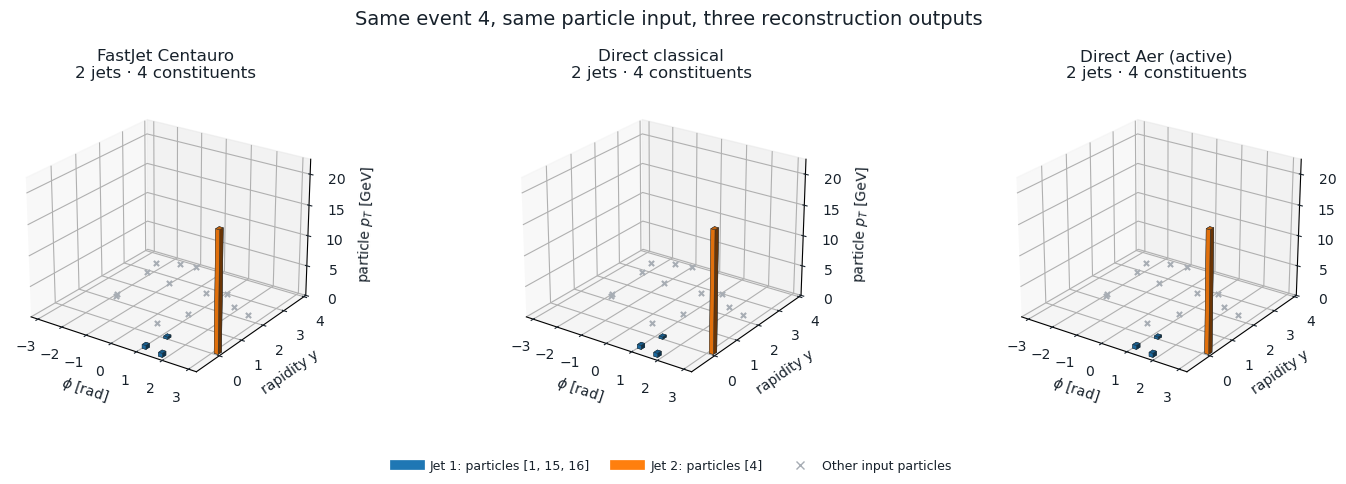

method,jet,particles,px_GeV,py_GeV,pz_GeV,energy_GeV,pT_GeV
FastJet Centauro,1,"1, 15, 16",0.247026,1.478569,-0.955593,2.195517,1.499062
FastJet Centauro,2,4,-19.467957,0.000000,2.235366,19.596369,19.467957
Direct classical,1,"1, 15, 16",0.247026,1.478569,-0.955593,2.195517,1.499062
Direct classical,2,4,-19.467957,0.000000,2.235366,19.596369,19.467957
Direct Aer (active),1,"1, 15, 16",0.247026,1.478569,-0.955593,2.195517,1.499062
Direct Aer (active),2,4,-19.467957,0.000000,2.235366,19.596369,19.467957


In [2]:
def canonical_jets(event, method):
    result = {}
    selection = jets[(jets.event_index == event) & (jets.method == method)]
    for _, jet in selection.iterrows():
        links = members[(members.event_index == event) &
                        (members.method == method) & (members.jet_index == jet.jet_index)]
        key = tuple(sorted(links.particle_index.astype(int)))
        if not key or key in result:
            raise ValueError('Empty or duplicate jet constituent set.')
        result[key] = jet
    return result

event_particles = particles[particles.event_index == EVENT].set_index('particle_index')
reference = canonical_jets(EVENT, 'classical')
keys = sorted(reference)
colors = {key: plt.get_cmap('tab10')(i) for i, key in enumerate(keys)}
fig = plt.figure(figsize=(15, 4.8))
axes = []
maximum_pt = max(event_particles.loc[list(key), 'pt_GeV'].max() for key in keys)
y_min, y_max = event_particles.rapidity.min() - .2, event_particles.rapidity.max() + .2
for position, method in enumerate(METHODS, 1):
    ax = fig.add_subplot(1, 3, position, projection='3d')
    current = canonical_jets(EVENT, method)
    assigned = set()
    for key, jet in current.items():
        group = event_particles.loc[list(key)]
        phi = np.arctan2(group.py_GeV, group.px_GeV).to_numpy()
        rapidity = group.rapidity.to_numpy()
        height = group.pt_GeV.to_numpy()
        ax.bar3d(phi-.075, rapidity-.075, np.zeros(len(group)), .15, .15, height,
                 color=colors.get(key, '#d62728'), edgecolor='#263238', linewidth=.3, shade=True)
        assigned.update(key)
    other = event_particles.loc[~event_particles.index.isin(assigned)]
    ax.scatter(np.arctan2(other.py_GeV, other.px_GeV), other.rapidity,
               np.zeros(len(other)), c='#a7adb4', marker='x', s=14, depthshade=False)
    ax.set(xlabel=r'$\phi$ [rad]', ylabel='rapidity y', zlabel=r'particle $p_T$ [GeV]',
           xlim=(-np.pi-.15, np.pi+.15), ylim=(y_min, y_max), zlim=(0, maximum_pt*1.15),
           title=f'{LABELS[method]}\n{len(current)} jets · {len(assigned)} constituents')
    ax.view_init(elev=24, azim=-55)
    axes.append(ax)
legend = [Line2D([0], [0], color=colors[key], lw=7, label=f'Jet {i+1}: particles {list(key)}')
          for i, key in enumerate(keys)]
legend.append(Line2D([0], [0], color='#a7adb4', marker='x', linestyle='', label='Other input particles'))
fig.legend(handles=legend, loc='lower center', ncol=min(3, len(legend)), frameon=False, fontsize=9)
fig.suptitle(f'Same event {EVENT}, same particle input, three reconstruction outputs', fontsize=14)
fig.subplots_adjust(left=.02, right=.97, top=.82, bottom=.17, wspace=.14)
plt.show()

event_table = []
for method in METHODS:
    for key, jet in sorted(canonical_jets(EVENT, method).items()):
        event_table.append({'method': LABELS[method], 'jet': keys.index(key)+1 if key in keys else 'unmatched',
            'particles': ', '.join(map(str, key)), **{column: jet[column] for column in P4},
            'pT_GeV': np.hypot(jet.px_GeV, jet.py_GeV)})
display(pd.DataFrame(event_table).round(6).style.hide(axis='index'))

### Check all ten events, not only the picture

For every event, match final jets by their full constituent sets and compare
the independently stored $p_x,p_y,p_z,E$. An unmatched set is reported as a
failure, not silently paired to the closest jet. All values below are
calculated from the included particle/jet tables.

event,classical jets,fastjet jets,fastjet same constituents,fastjet max |Δp4| [GeV],active jets,active same constituents,active max |Δp4| [GeV]
0,2,2,True,0.000000,2,True,0.000000
1,2,2,True,0.000000,2,True,0.000000
2,2,2,True,0.000000,2,True,0.000000
3,2,2,True,0.000000,2,True,0.000000
4,2,2,True,0.000000,2,True,0.000000
5,2,2,True,0.000000,2,True,0.000000
6,2,2,True,0.000000,2,True,0.000000
7,2,2,True,0.000000,2,True,0.000000
8,2,2,True,0.000000,2,True,0.000000
9,2,2,True,0.000000,2,True,0.000000


20 reference jets across ten events. FastJet matches in 10/10 events; active matches in 10/10 events.


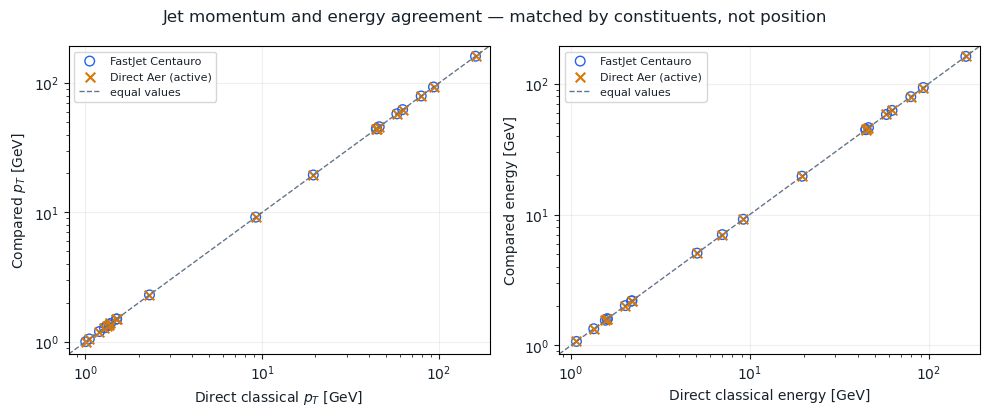

In [3]:
checks, pairs = [], []
for event in sorted(particles.event_index.unique()):
    base = canonical_jets(event, 'classical')
    record = {'event': int(event), 'classical jets': len(base)}
    for method in ('fastjet', 'active'):
        compared = canonical_jets(event, method)
        same_sets = set(base) == set(compared)
        differences = []
        for key in set(base) & set(compared):
            a, b = base[key], compared[key]
            differences.extend(abs(float(a[c])-float(b[c])) for c in P4)
            pairs.append({'event': event, 'method': method,
                'reference_pT': np.hypot(a.px_GeV, a.py_GeV), 'comparison_pT': np.hypot(b.px_GeV, b.py_GeV),
                'reference_E': a.energy_GeV, 'comparison_E': b.energy_GeV})
        record[f'{method} jets'] = len(compared)
        record[f'{method} same constituents'] = same_sets
        record[f'{method} max |Δp4| [GeV]'] = max(differences) if same_sets and differences else np.nan
    checks.append(record)
jet_checks = pd.DataFrame(checks)
display(jet_checks.style.hide(axis='index').format(precision=6))
matched_jets = int(jets[jets.method == 'classical'].shape[0])
print(f'{matched_jets} reference jets across ten events. '
      f'FastJet matches in {jet_checks["fastjet same constituents"].sum()}/10 events; '
      f'active matches in {jet_checks["active same constituents"].sum()}/10 events.')

paired_jets = pd.DataFrame(pairs)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, variable, label in zip(axes, ['pT', 'E'], [r'$p_T$', 'energy']):
    for method, color, marker in [('fastjet', '#2563eb', 'o'), ('active', '#d97706', 'x')]:
        group = paired_jets[paired_jets.method == method]
        marker_colors = {'facecolors':'none', 'edgecolors':color} if marker == 'o' else {'color':color}
        ax.scatter(group[f'reference_{variable}'], group[f'comparison_{variable}'],
                   label=LABELS[method], marker=marker, s=48, **marker_colors)
    values = paired_jets[[f'reference_{variable}', f'comparison_{variable}']].to_numpy()
    assert np.all(values > 0), 'Log axes require positive jet pT/energy.'
    lo, hi = values.min()*.8, values.max()*1.2
    ax.plot([lo, hi], [lo, hi], '--', color='#64748b', lw=1, label='equal values')
    ax.set(xscale='log', yscale='log', xlim=(lo, hi), ylim=(lo, hi),
           xlabel=f'Direct classical {label} [GeV]', ylabel=f'Compared {label} [GeV]')
    ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.suptitle('Jet momentum and energy agreement — matched by constituents, not position')
fig.tight_layout()
plt.show()

**Observed result:** the 20 final jets agree in constituents and stored four-momenta
across all three methods in these ten fixed events. Zero residual here means
equality of the stored values, not precision beyond their storage format.

This is a sample-level reconstruction result. FastJet has different area
handling, Direct has no area estimator, and the sample is small: this is not
a proof of general algorithmic or detector-physics equivalence.

## 3. Same final jets, possibly different decision sequences

The recorded event-4 sequence contains two pair merges followed by beam
decisions. Local candidate indices change when the candidate list is rebuilt.
Different indices can also correspond to **tied minima**: equality of final
jets does not require identical ordering of every internal action.

The table and plots use actual classical/active decisions. The classical
selection scans $M$ candidates. Encoding a list into $\lceil\log_2M\rceil$
qubits does not make preparing or reading that list free.

,candidates,classical action,active action,active qubits,active selects minimum,minimum distance,active tie status
iteration,,,,,,,
0,78,"merge(1, 11)","merge(1, 11)",7,True,0.123976,unique_minimum
1,66,"merge(9, 10)","merge(9, 10)",7,True,0.726383,unique_minimum
2,55,beam(0),beam(1),6,True,1.000000,divergent_tie
3,45,beam(0),beam(1),6,True,1.000000,divergent_tie
4,36,beam(0),beam(5),6,True,1.000000,divergent_tie
5,28,beam(0),beam(0),5,True,1.000000,tied_consistent
6,21,beam(0),beam(0),5,True,1.000000,tied_consistent
7,15,beam(0),beam(0),4,True,1.000000,tied_consistent
8,10,beam(0),beam(0),4,True,1.000000,tied_consistent


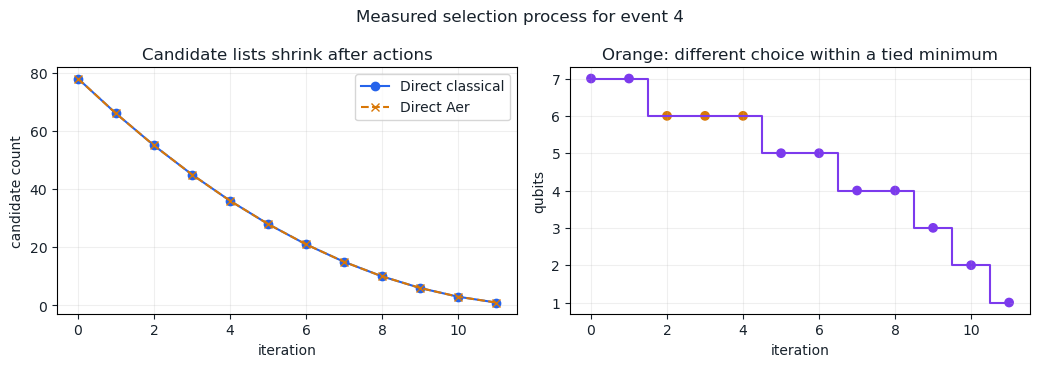

Active applied the worker in 12/12 steps; 3 tied choices differ from its classical tie rule.


In [4]:
process = steps.copy()
process['action'] = process.apply(lambda r: f"merge({int(r.decision_i)}, {int(r.decision_j)})"
    if r.decision_kind == 'pair' else f"beam({int(r.decision_i)})", axis=1)
process['is minimum'] = np.isclose(process.selected_distance, process.min_distance, rtol=1e-12, atol=1e-15)
left = process[process.method == 'classical'].set_index('iteration')
right = process[process.method == 'active'].set_index('iteration')
decision_table = pd.DataFrame({'candidates':left.candidate_count,
    'classical action':left.action, 'active action':right.action,
    'active qubits':right.qubits, 'active selects minimum':right['is minimum'],
    'minimum distance':right.min_distance, 'active tie status':right.divergent_tie_status})
display(decision_table.round(6))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
axes[0].plot(left.index, left.candidate_count, 'o-', label='Direct classical', color='#2563eb')
axes[0].plot(right.index, right.candidate_count, 'x--', label='Direct Aer', color='#d97706')
axes[0].set(xlabel='iteration', ylabel='candidate count', title='Candidate lists shrink after actions')
axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].step(right.index, right.qubits, where='mid', color='#7c3aed', label='encoded qubits')
axes[1].scatter(right.index, right.qubits, c=np.where(right.divergent_tie_status == 'divergent_tie', '#d97706', '#7c3aed'))
axes[1].set(xlabel='iteration', ylabel='qubits', title='Orange: different choice within a tied minimum')
axes[1].grid(alpha=.2)
fig.suptitle('Measured selection process for event 4')
fig.tight_layout(); plt.show()
print(f'Active applied the worker in {int(right.qiskit_applied.sum())}/{len(right)} steps; '
      f'{int((right.divergent_tie_status == "divergent_tie").sum())} tied choices differ from its classical tie rule.')

## 4. How reliable is selection?

Two different experiments answer different questions:

- **Operational reconstruction:** 10 fixed events × 30 blocks × 3 methods =
  900 measured processes. The seed is fixed; compare the complete Direct jets
  for each matched event/block.
- **Prepared selection:** 88 frozen candidate lists × 30 varied seeds =
  2,640 calls **per scenario**. This tests the isolated selector, not complete
  alternate event histories. There are 59 tied-minimum lists among the 88.

Choosing a different valid tied minimum is not a nonminimum-selection error.
Conversely, success in the event sample does not guarantee every future
sampled choice will be correct.

In [5]:
active_runs = operational[operational['mode'] == 'direct_active']
quality = []
for label, frame in prepared.items():
    successes = int(frame.minimum_distance_success.sum())
    exact = int(frame.first_index_match.sum())
    quality.append({'scenario':label, 'calls':len(frame), 'minimum selected':successes,
        'minimum success [%]':100*successes/len(frame), 'exact first index [%]':100*exact/len(frame),
        'nonminimum choices':len(frame)-successes})
display(pd.DataFrame(quality).round(2).style.hide(axis='index'))
print(f'Full Direct partition agreement: {int(active_runs.direct_partition_match.sum())}/{len(active_runs)}.')
print(f'Applied proposals: {int(active_runs.qiskit_applied_count.sum())}; '
      f'fallbacks: {int(active_runs.fallback_count.sum())}; '
      f'service errors/timeouts: {int(active_runs.service_error_count.sum()+active_runs.timeout_count.sum())}.')
failures = prepared['Production defaults'].loc[~prepared['Production defaults'].minimum_distance_success,
    ['input_id', 'repeat', 'sampled_index']]
print('Nonminimum selections in the primary prepared scenario:')
display(failures.reset_index(drop=True))

scenario,calls,minimum selected,minimum success [%],exact first index [%],nonminimum choices
Production defaults,2640,2635,99.810000,54.240000,5
One-thread control,2640,2635,99.810000,54.240000,5


Full Direct partition agreement: 300/300.
Applied proposals: 2640; fallbacks: 0; service errors/timeouts: 0.
Nonminimum selections in the primary prepared scenario:


,input_id,repeat,sampled_index
0,e9:i1,12,24
1,e9:i1,15,12
2,e9:i1,17,21
3,e9:i1,20,12
4,e9:i1,23,27


## 5. What does the complete process cost?

**Operational wall time** includes fresh EICrecon process startup, loading and
skipping to the selected event, reconstruction and writing output. It is not
an isolated clustering timer. Worker readiness is measured separately.
FastJet's area handling also makes it a contextual, not identical-work, timer.

The left plot shows medians and observed min–max ranges (**not confidence
intervals**). The right plot separates the ten events; each point is the
median of 30 blocks.

,processes,median [ms],mean [ms],SD [ms],min [ms],max [ms]
FastJet Centauro,300,1495.72,1490.07,264.16,936.85,2443.00
Direct classical,300,1009.12,1064.88,131.92,946.93,1714.34
Direct Aer,300,1146.05,1309.88,406.90,948.05,3509.78


Paired active − classical: mean 245.00 ms; median 61.89 ms.
Separate worker readiness median: 1603.22 ms.


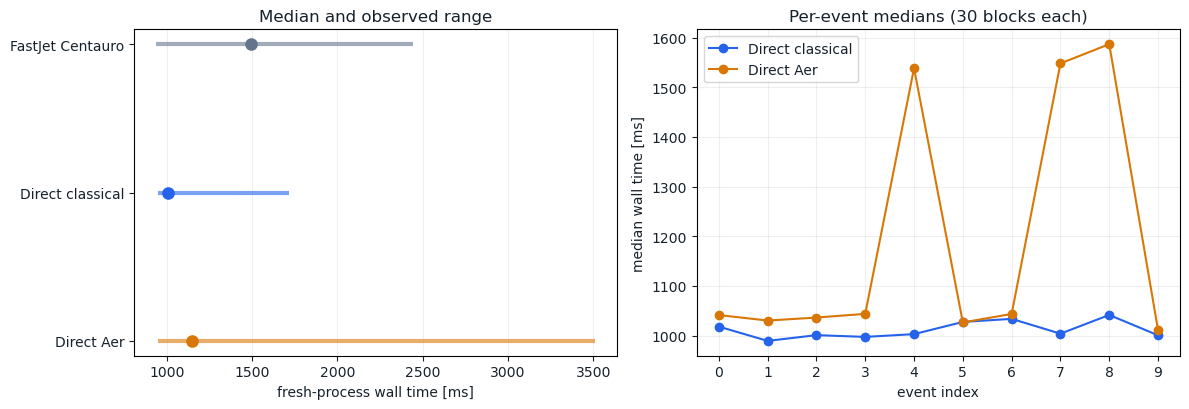

In [6]:
ORDER = ['fastjet_centauro', 'direct_classical', 'direct_active']
NAMES = ['FastJet Centauro', 'Direct classical', 'Direct Aer']
time_table = operational.groupby('mode').eicrecon_wall_ms.agg(['count', 'median', 'mean', 'std', 'min', 'max']).loc[ORDER]
time_table.index = NAMES
display(time_table.rename(columns={'count':'processes', 'median':'median [ms]',
    'mean':'mean [ms]', 'std':'SD [ms]', 'min':'min [ms]', 'max':'max [ms]'}).round(2))

paired_wall = operational.pivot(index=['block','event_index'], columns='mode', values='eicrecon_wall_ms')
delta = paired_wall.direct_active - paired_wall.direct_classical
print(f'Paired active − classical: mean {delta.mean():.2f} ms; median {delta.median():.2f} ms.')
print(f'Separate worker readiness median: {active_runs.worker_cold_start_ms.median():.2f} ms.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for i, (mode, name, color) in enumerate(zip(ORDER, NAMES, ['#64748b','#2563eb','#d97706'])):
    values = operational.loc[operational['mode'] == mode, 'eicrecon_wall_ms']
    axes[0].hlines(i, values.min(), values.max(), color=color, lw=3, alpha=.6)
    axes[0].scatter(values.median(), i, color=color, s=65, zorder=3)
axes[0].set(yticks=range(3), yticklabels=NAMES, xlabel='fresh-process wall time [ms]', title='Median and observed range')
axes[0].invert_yaxis(); axes[0].grid(axis='x', alpha=.2)
for mode, name, color in zip(ORDER[1:], NAMES[1:], ['#2563eb','#d97706']):
    medians = operational.loc[operational['mode'] == mode].groupby('event_index').eicrecon_wall_ms.median()
    axes[1].plot(medians.index, medians, 'o-', color=color, label=name)
axes[1].set(xlabel='event index', ylabel='median wall time [ms]', title='Per-event medians (30 blocks each)', xticks=range(10))
axes[1].legend(); axes[1].grid(alpha=.2)
fig.tight_layout(); plt.show()

## 6. What if the circuit has already been prepared?

The isolated comparison builds and decomposes each input-specific circuit
**before** timing. Each measured call still executes Aer and decodes its
counts; no sampled output is reused. The native C++ selector sees the same
candidate list and is measured in batches to reduce clock overhead.

The primary scenario uses normal Aer defaults. A separate one-thread campaign
is shown without pooling the data: its native baseline also differs, so their
difference is not a causal measurement of thread policy alone.

External construction/decomposition, candidate enumeration, IPC and I/O are
excluded here. Execution of state-preparation gates, simulator/interface
overhead and decoding are **not** excluded. Live reconstruction still needs
to prepare the circuit when the candidate distances change.

scenario,C++ median [ns],Aer execution median [ms],decode median [ms],usable result median [ms],usable result p95 [ms]
Production defaults,34.164300,5.739800,1.211900,7.092100,20.511800
One-thread control,19.910500,2.558400,0.545200,3.134800,8.626600


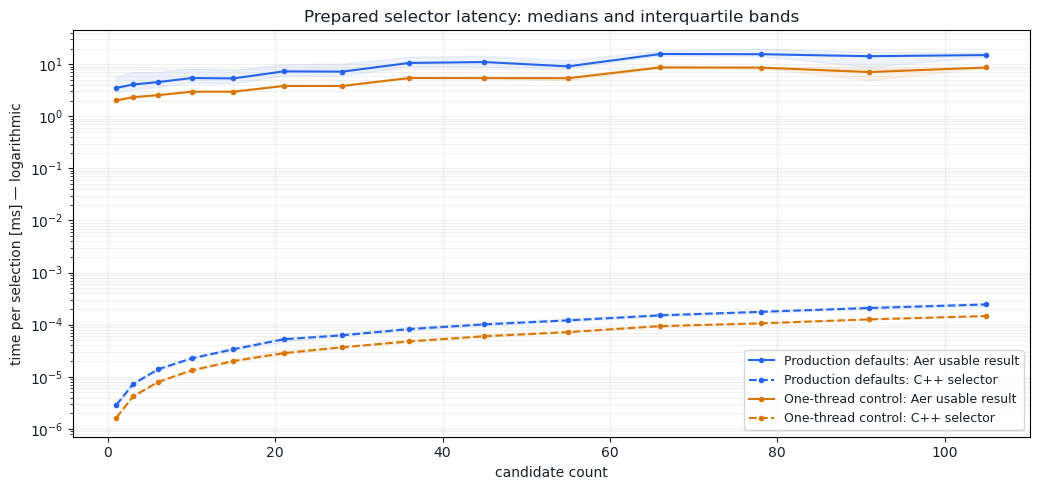

In [7]:
prepared_times = []
for label, frame in prepared.items():
    prepared_times.append({'scenario':label, 'C++ median [ns]':frame.classical_ns.median(),
        'Aer execution median [ms]':frame.aer_sampling_ms.median(),
        'decode median [ms]':frame.aer_decode_ms.median(),
        'usable result median [ms]':frame.aer_total_ms.median(),
        'usable result p95 [ms]':frame.aer_total_ms.quantile(.95)})
display(pd.DataFrame(prepared_times).round(4).style.hide(axis='index'))

fig, ax = plt.subplots(figsize=(10.5, 5))
for label, color in [('Production defaults','#2563eb'), ('One-thread control','#d97706')]:
    frame = prepared[label]
    grouped = frame.groupby('candidate_count')
    for column, scale, linestyle, suffix in [('aer_total_ms',1,'-','Aer usable result'),
                                           ('classical_ns',1e-6,'--','C++ selector')]:
        median = grouped[column].median()*scale
        lower = grouped[column].quantile(.25)*scale
        upper = grouped[column].quantile(.75)*scale
        assert (lower > 0).all(), 'Log timing requires positive values.'
        ax.plot(median.index, median, linestyle, color=color, marker='o', markersize=3,
                label=f'{label}: {suffix}')
        ax.fill_between(median.index, lower, upper, color=color, alpha=.08)
ax.set(yscale='log', xlabel='candidate count', ylabel='time per selection [ms] — logarithmic',
       title='Prepared selector latency: medians and interquartile bands')
ax.grid(which='both', alpha=.18)
ax.legend(fontsize=9, loc='best')
fig.tight_layout(); plt.show()

## Takeaway

**Same measured final jets, different selection paths and costs.** In this
ten-event sample the three methods return the same 20 jets; Direct classical
and active also agree in all 300 repeated operational comparisons. The
prepared selector succeeds in 2,635/2,640 varied-seed calls, not every call.

Even with external circuit preparation excluded, the simulated selector is
slower than the native scan. This demonstrates an integration and a measured
cost/quality trade-off, **not quantum advantage or physical QPU timing**.
Ten selected events are not broad physics validation, and repeated timing
blocks do not increase event diversity. Area estimation is not compared.

All data used above are in [`data/`](data/README.md) and the repository's
[`recorded measurements`](../benchmark/results/2026-10-04/README.md).